## Multiple Object Video Detection. Data Understanding and Preprocessing

HW2, UCU AI 2026. Notebook 1 of the pipeline (runs on **Kaggle CPU**, no GPU needed: turn the accelerator off to save GPU quota).

Data: VisDrone2019-VID drone clips, 8 classes (person, bicycle, car, van, truck, tricycle, bus, motor).

What this notebook does:
1. EDA: clips and resolutions, class balance, object sizes, scene density, occlusion, ignored regions, temporal redundancy
2. Validation design: sequence-level split, train/val leakage check, GroupKFold folds over clips
3. Anchor statistics for the anchor-based detectors
4. Export of a preprocessed training set (frame subsampling, ignored regions masked, resized) + YOLO / COCO labels, verified visually
5. Writes everything (exported dataset, config json, figures) to `/kaggle/working`; after **Save Version** the output can be attached as input to the GPU notebooks

### Setup

Attach the competition data to the notebook (**Add Input → Competitions**). It is mounted read-only under `/kaggle/input`.

In [11]:
!ls /kaggle/input/*

multiple-object-video-detection-hw-2-ucu-ai-2026


In [12]:
import os, json, re, random, shutil, time
from pathlib import Path
from multiprocessing import Pool

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import cv2
from tqdm.auto import tqdm

plt.style.use("default")
pd.set_option("display.width", 200)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)

CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]
PALETTE = sns.color_palette("tab10", len(CLASSES))

DATA = Path("/kaggle/input")                  # read-only competition data
WORK = Path("/kaggle/working")                # saved as notebook output (20 GB limit)
OUT = WORK / "vd_prep"                        # exported training set
FIG_DIR = WORK / "figures"                    # figures for report.md
FIG_DIR.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight")

In [13]:
# locate split folders regardless of how the archive is nested
coco_files = sorted(DATA.rglob("annotations_coco.json"))
TRAIN_DIR = next(p.parent for p in coco_files if p.parent.name == "train")
VAL_DIR = next(p.parent for p in coco_files if p.parent.name == "val")
TEST_CSV = next(DATA.rglob("test_images.csv"))
print(TRAIN_DIR, VAL_DIR, TEST_CSV, sep="\n")

/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026/train
/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026/val
/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026/test_images.csv


### Load annotations

COCO json is used as the main source (it has `track_id`, `occlusion`, `truncation`, `orig_category_id`, `video`, `frame_id`).
Boxes are `[x, y, w, h]` in pixels, `category_id` is 1-based, ignored regions are `iscrowd = 1`.
The provided YOLO txt labels are cross-checked against it later.

In [14]:
def resolve_paths(imgs, split_dir):
    # map COCO file_name -> real jpg path via (clip folder, file name)
    index = {(p.parent.name, p.name): p for p in (split_dir / "images").rglob("*.jpg")}
    paths = []
    for r in imgs.itertuples():
        fn = Path(r.file_name)
        p = index.get((fn.parent.name, fn.name)) or index.get((r.video, fn.name))
        paths.append(None if p is None else str(p))
    missing = sum(p is None for p in paths)
    assert missing == 0, f"{missing} images from {split_dir} not found on disk"
    return paths

def load_coco(split_dir, split):
    with open(split_dir / "annotations_coco.json") as f:
        coco = json.load(f)
    imgs = pd.DataFrame(coco["images"]).rename(columns={"id": "image_id"})
    anns = pd.DataFrame(coco["annotations"]).rename(columns={"id": "ann_id"})
    del coco
    imgs["path"] = resolve_paths(imgs, split_dir)
    imgs["split"] = split

    anns[["x", "y", "w", "h"]] = np.array(anns["bbox"].tolist(), dtype=np.float32)
    anns = anns.drop(columns=["bbox", "segmentation"], errors="ignore")
    if "iscrowd" not in anns:
        anns["iscrowd"] = 0
    anns = anns.merge(imgs[["image_id", "video", "frame_id", "width", "height"]], on="image_id")
    anns["split"] = split

    objs = anns[anns.iscrowd == 0].copy()
    ign = anns[anns.iscrowd == 1].copy()
    objs["cls"] = objs.category_id.astype(int) - 1
    objs["cls_name"] = pd.Categorical(objs.cls.map(dict(enumerate(CLASSES))), categories=CLASSES)
    return imgs, objs, ign

t0 = time.time()
tr_imgs, tr_objs, tr_ign = load_coco(TRAIN_DIR, "train")
va_imgs, va_objs, va_ign = load_coco(VAL_DIR, "val")

# image_id is unique only inside a split -> always key on (split, image_id)
imgs = pd.concat([tr_imgs, va_imgs], ignore_index=True)
objs = pd.concat([tr_objs, va_objs], ignore_index=True)
ign = pd.concat([tr_ign, va_ign], ignore_index=True)
objs["uid"] = np.arange(len(objs))
test = pd.read_csv(TEST_CSV)
del tr_imgs, tr_objs, tr_ign, va_imgs, va_objs, va_ign

print(f"loaded in {time.time() - t0:.0f} s")
print("image columns:", list(imgs.columns))
print("object columns:", list(objs.columns))
display(objs.head())

loaded in 30 s
image columns: ['image_id', 'file_name', 'width', 'height', 'video_id', 'video', 'frame_id', 'path', 'split']
object columns: ['ann_id', 'image_id', 'category_id', 'area', 'iscrowd', 'truncation', 'occlusion', 'track_id', 'orig_category_id', 'ignore', 'x', 'y', 'w', 'h', 'video', 'frame_id', 'width', 'height', 'split', 'cls', 'cls_name', 'uid']


,ann_id,image_id,category_id,area,iscrowd,truncation,occlusion,track_id,orig_category_id,ignore,...,w,h,video,frame_id,width,height,split,cls,cls_name,uid
0,1,1,1,3080,0,0.0,0.0,2.0,1,NaN,...,35.0,88.0,uav0000013_00000_v,1,1344,756,train,0,person,0
1,2,1,1,3060,0,0.0,1.0,3.0,1,NaN,...,36.0,85.0,uav0000013_00000_v,1,1344,756,train,0,person,1
2,3,1,6,9918,0,1.0,0.0,4.0,7,NaN,...,87.0,114.0,uav0000013_00000_v,1,1344,756,train,5,tricycle,2
3,4,1,1,2528,0,0.0,0.0,5.0,1,NaN,...,32.0,79.0,uav0000013_00000_v,1,1344,756,train,0,person,3
4,5,1,1,1008,0,0.0,0.0,6.0,1,NaN,...,21.0,48.0,uav0000013_00000_v,1,1344,756,train,0,person,4


In [45]:
overview = []
for s in ["train", "val"]:
    i, o, g = imgs[imgs.split == s], objs[objs.split == s], ign[ign.split == s]
    overview.append({"split": s, "clips": i.video.nunique(), "frames": len(i), "objects": len(o),
                     "objects/frame": len(o) / len(i), "ignore regions": len(g)})
overview.append({"split": "test", "clips": test["clip"].nunique(), "frames": len(test)})
display(pd.DataFrame(overview).set_index("split").round(1))

,clips,frames,objects,objects/frame,ignore regions
split,,,,,
train,56,24201,1105516.0,45.7,510744.0
val,7,2846,114132.0,40.1,31960.0
test,48,3811,NaN,NaN,NaN


### Image resolution per clip

In [16]:
res = pd.concat([
    imgs.groupby(["split", "video"]).agg(width=("width", "first"), height=("height", "first"),
                                         frames=("image_id", "size"), n_res=("width", "nunique")).reset_index(),
    test.groupby("clip").agg(width=("width", "first"), height=("height", "first"),
                             frames=("image_id", "size"), n_res=("width", "nunique")).reset_index()
        .rename(columns={"clip": "video"}).assign(split="test"),
], ignore_index=True)
res["resolution"] = res.width.astype(str) + "x" + res.height.astype(str)

print("clips with more than one resolution:", (res.n_res > 1).sum())
display(pd.crosstab(res.resolution, res.split, margins=True).sort_values("All", ascending=False))
print("frames per clip:")
display(res.groupby("split").frames.describe().round(0))

clips with more than one resolution: 0


split,test,train,val,All
resolution,,,,
All,48,56,7,111
1904x1071,0,30,2,32
1344x756,7,11,2,20
1360x764,18,0,0,18
2688x1512,0,11,1,12
1920x1080,11,1,0,12
960x540,5,0,0,5
1904x1072,4,0,0,4
680x382,3,0,0,3


frames per clip:


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,48.0,79.0,35.0,35.0,49.0,74.0,108.0,148.0
train,56.0,432.0,275.0,58.0,224.0,384.0,550.0,1424.0
val,7.0,407.0,268.0,184.0,254.0,349.0,414.0,978.0


**Observations:**
- Every clip has a single resolution, but resolutions differ a lot. Train: 1904x1071 (30 clips), 1344x756 (11), 2688x1512 (11); val has one 4K clip (3840x2160). Test is smaller: 1360x764 (18), 1920x1080 (11), 1344x756 (7), 960x540 (5), 680x382 (3), nothing above 1920 px.
- Clip length varies from 58 to 1424 frames (train), so long clips dominate if frames are sampled uniformly.
- Object size in pixels depends on the clip resolution, so all frames are resized to one fixed input size before training.

### Class distribution

split,train,val,train %,val %
cls_name,,,,
person,328701,50312,29.73,44.08
bicycle,40255,6022,3.64,5.28
car,505301,31821,45.71,27.88
van,46940,6842,4.25,5.99
truck,30498,1359,2.76,1.19
tricycle,41349,5487,3.74,4.81
bus,9653,264,0.87,0.23
motor,102819,12025,9.30,10.54


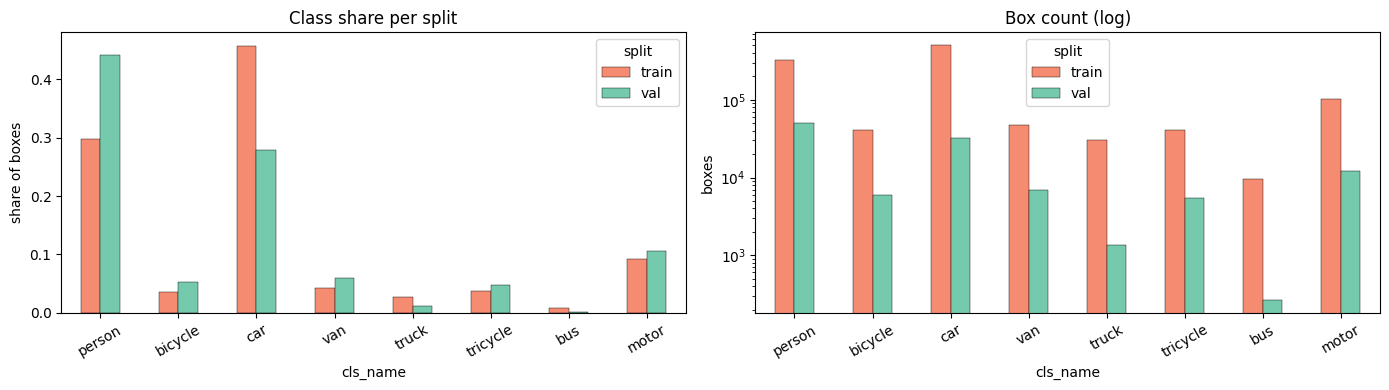

In [17]:
cnt = objs.groupby(["cls_name", "split"], observed=False).size().unstack()
share = cnt / cnt.sum()
display(pd.concat([cnt, (share * 100).round(2).add_suffix(" %")], axis=1))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
share.plot.bar(ax=ax[0], color=["#F58B70", "#75C9AC"], edgecolor="black", linewidth=0.3)
ax[0].set(title="Class share per split", ylabel="share of boxes"); ax[0].tick_params(axis="x", rotation=30)
cnt.plot.bar(ax=ax[1], logy=True, color=["#F58B70", "#75C9AC"], edgecolor="black", linewidth=0.3)
ax[1].set(title="Box count (log)", ylabel="boxes"); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); savefig("class_distribution"); plt.show()

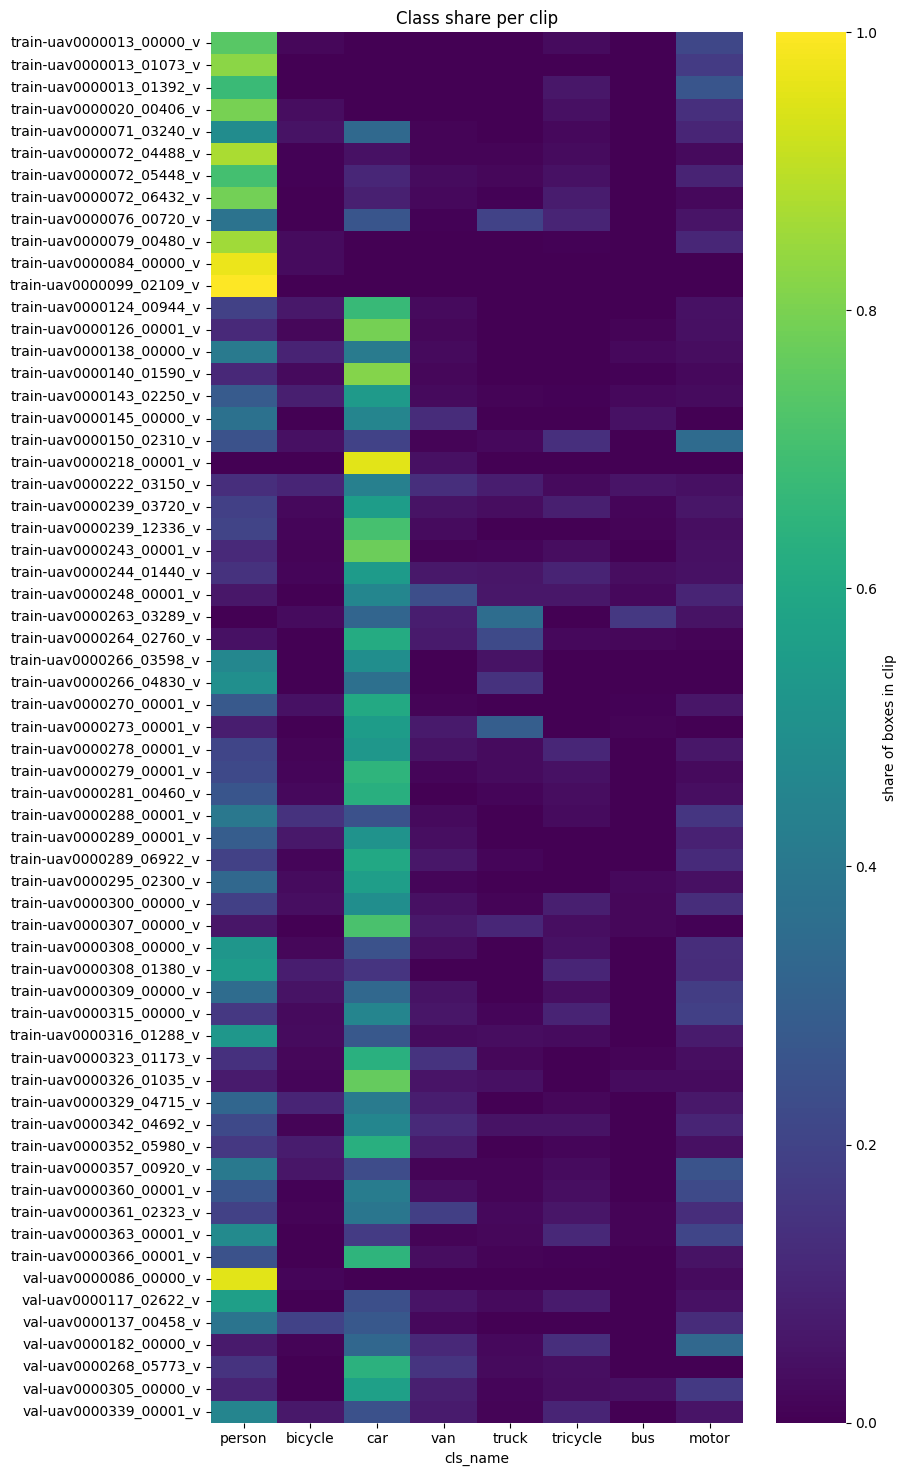

share of clips where class appears at all:
 cls_name
person      0.98
bicycle     0.73
car         0.87
van         0.83
truck       0.70
tricycle    0.70
bus         0.40
motor       0.89


In [18]:
# how the class mix changes between sequences
per_clip = pd.crosstab([objs.split, objs.video], objs.cls_name, normalize="index")
fig, ax = plt.subplots(figsize=(9, 0.22 * len(per_clip) + 1))
sns.heatmap(per_clip, cmap="viridis", ax=ax, cbar_kws={"label": "share of boxes in clip"})
ax.set(title="Class share per clip", ylabel="")
plt.tight_layout(); savefig("class_share_per_clip"); plt.show()

clip_presence = (pd.crosstab(objs.video, objs.cls_name) > 0).mean()
print("share of clips where class appears at all:\n", clip_presence.round(2).to_string())

In [19]:
# original VisDrone categories -> 8 competition classes (and what became ignored regions)
if "orig_category_id" in objs:
    display(pd.crosstab(objs.orig_category_id, objs.cls_name))
    print("orig categories among ignored regions:", ign.orig_category_id.value_counts().to_dict())

cls_name,person,bicycle,car,van,truck,tricycle,bus,motor
orig_category_id,,,,,,,,
1,266709,0,0,0,0,0,0,0
2,112304,0,0,0,0,0,0,0
3,0,46277,0,0,0,0,0,0
4,0,0,537122,0,0,0,0,0
5,0,0,0,53782,0,0,0,0
6,0,0,0,0,31857,0,0,0
7,0,0,0,0,0,32107,0,0
8,0,0,0,0,0,14729,0,0
9,0,0,0,0,0,0,9917,0


orig categories among ignored regions: {0: 530904, 11: 11800}


**Observations:**
- Strong class imbalance: car 45.7 % and person 29.7 % of train boxes, bus only 0.9 % and truck 2.8 %. Bus appears in 40 % of clips, truck and tricycle in 70 %.
- Val has a different mix (person 44 %, car 28 %, bus 0.2 % with just 264 boxes), and the class mix changes a lot between clips. Per-class AP of bus and truck will be noisy.
- The 10 -> 8 class mapping is as expected (pedestrian + people -> person, tricycle + awning-tricycle -> tricycle). Ignored regions come from orig class 0 (531k) and "others" 11 (12k).

### Object sizes

COCO size buckets: small < 32², medium < 96², large ≥ 96² px (original resolution).

In [20]:
objs["area"] = objs.w * objs.h
objs["sqrt_area"] = np.sqrt(objs.area)
objs["rel_size"] = objs.sqrt_area / np.sqrt(objs.width * objs.height)   # resolution independent
objs["size_bin"] = pd.cut(objs.area, [0, 32**2, 96**2, np.inf], labels=["small", "medium", "large"], right=False)

sz = pd.crosstab(objs.cls_name, objs.size_bin, normalize="index")
sz.loc["ALL"] = objs.size_bin.value_counts(normalize=True)
display((sz * 100).round(1))
display(objs.groupby("split").sqrt_area.describe(percentiles=[.05, .25, .5, .75, .95]).round(1))

size_bin,small,medium,large
cls_name,,,
person,37.5,61.7,0.7
bicycle,21.6,75.6,2.8
car,15.9,64.9,19.2
van,19.4,63.8,16.7
truck,9.1,57.5,33.4
tricycle,20.7,65.3,14.0
bus,4.0,39.3,56.7
motor,31.4,66.8,1.7
ALL,24.4,64.1,11.6


,count,mean,std,min,5%,25%,50%,75%,95%,max
split,,,,,,,,,,
train,1105516.0,56.6,38.3,7.7,19.7,32.0,45.8,67.9,130.2,703.0
val,114132.0,61.9,43.9,9.8,22.6,35.5,52.4,73.2,130.7,399.5


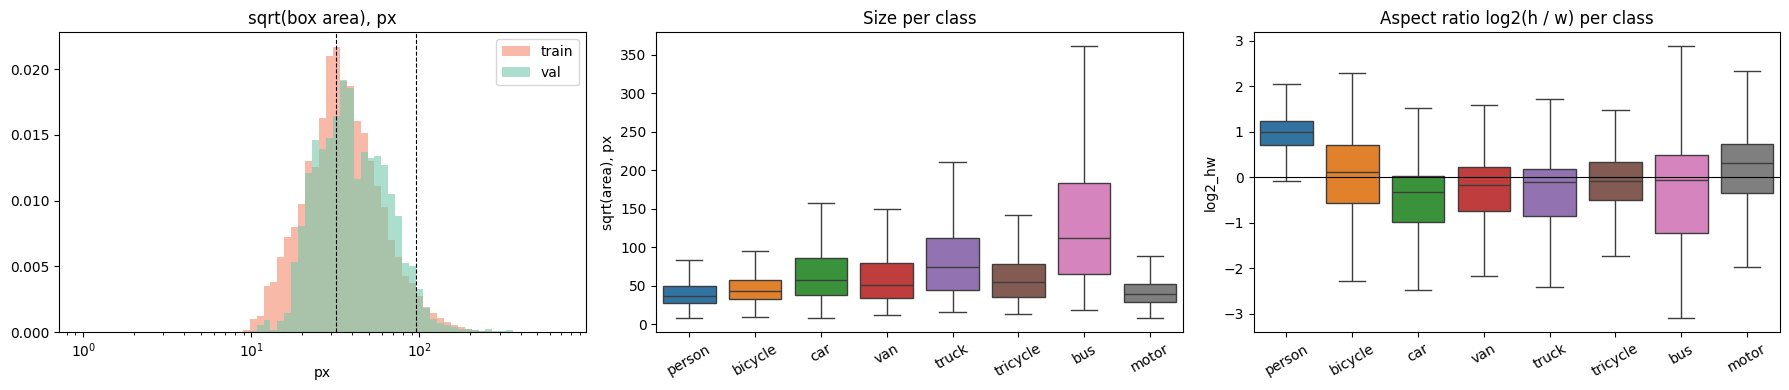

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
bins = np.logspace(0, np.log10(objs.sqrt_area.max() + 1), 70)
for s, c in [("train", "#F58B70"), ("val", "#75C9AC")]:
    ax[0].hist(objs.loc[objs.split == s, "sqrt_area"], bins=bins, alpha=0.6, density=True, label=s, color=c)
for t in (32, 96):
    ax[0].axvline(t, color="black", ls="--", lw=0.8)
ax[0].set(xscale="log", title="sqrt(box area), px", xlabel="px"); ax[0].legend()

sns.boxplot(data=objs, x="cls_name", y="sqrt_area", showfliers=False, ax=ax[1], palette=PALETTE, hue="cls_name", legend=False)
ax[1].set(title="Size per class", xlabel="", ylabel="sqrt(area), px"); ax[1].tick_params(axis="x", rotation=30)

objs["log2_hw"] = np.log2(objs.h / objs.w.clip(lower=1))
sns.boxplot(data=objs, x="cls_name", y="log2_hw", showfliers=False, ax=ax[2], palette=PALETTE, hue="cls_name", legend=False)
ax[2].axhline(0, color="black", lw=0.8)
ax[2].set(title="Aspect ratio log2(h / w) per class", xlabel=""); ax[2].tick_params(axis="x", rotation=30)
plt.tight_layout(); savefig("object_sizes"); plt.show()

,median_px,median_rel,width
count,63.000,63.000,63.000
mean,51.181,0.035,1998.984
std,14.795,0.009,522.496
min,24.495,0.017,1344.000
25%,41.235,0.030,1904.000
50%,48.083,0.034,1904.000
75%,57.498,0.039,2304.000
max,86.822,0.061,3840.000


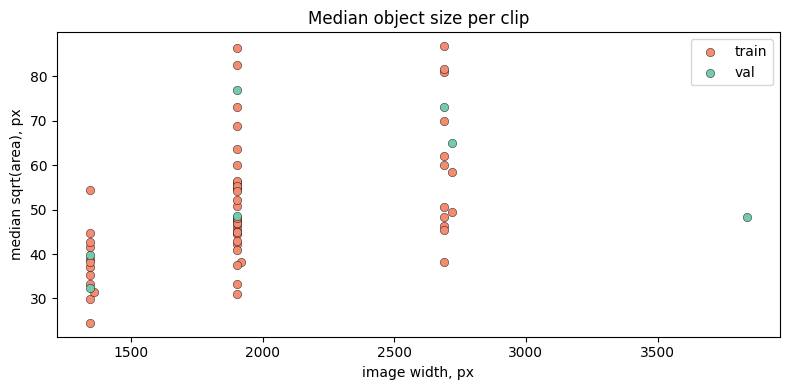

In [22]:
# relative size by clip: different altitudes / resolutions give very different object scales
clip_size = objs.groupby(["split", "video"]).agg(median_px=("sqrt_area", "median"),
                                                 median_rel=("rel_size", "median"),
                                                 width=("width", "first")).reset_index()
display(clip_size.describe().round(3))

fig, ax = plt.subplots(figsize=(8, 4))
for s, c in [("train", "#F58B70"), ("val", "#75C9AC")]:
    d = clip_size[clip_size.split == s]
    ax.scatter(d.width, d.median_px, label=s, color=c, edgecolor="black", linewidth=0.3)
ax.set(xlabel="image width, px", ylabel="median sqrt(area), px", title="Median object size per clip")
ax.legend(); plt.tight_layout(); savefig("size_per_clip"); plt.show()

##### Input resolution vs object size

How many boxes become tiny if each image is resized so the long side equals `S` (both up- and downscaling, as YOLO / DETR letterboxing does).

In [23]:
tr = objs[objs.split == "train"]
long_side = np.maximum(tr.width, tr.height)
min_side = np.minimum(tr.w, tr.h)

rows = []
for S in [640, 800, 960, 1024, 1280, "original"]:
    scale = 1.0 if S == "original" else S / long_side
    mn = min_side * scale
    rows.append({"long side": S, "min side < 4px": (mn < 4).mean(), "< 8px": (mn < 8).mean(),
                 "< 16px": (mn < 16).mean(), "median min side": mn.median(),
                 "COCO-small share": (tr.area * scale**2 < 32**2).mean()})
display(pd.DataFrame(rows).set_index("long side").round(3))

,min side < 4px,< 8px,< 16px,median min side,COCO-small share
long side,,,,,
640,0.017,0.220,0.693,12.101,0.890
800,0.010,0.124,0.538,15.126,0.819
960,0.007,0.059,0.406,18.151,0.735
1024,0.004,0.043,0.360,19.361,0.692
1280,0.000,0.017,0.220,24.202,0.542
original,0.000,0.000,0.059,36.000,0.249


**Observations:**
- Objects are small: median sqrt(area) is 46 px at original resolution (24 % COCO-small, 64 % medium, 12 % large).
- This depends on the input size: with the long side resized to 960, 74 % of boxes are COCO-small, 41 % have a short side under 16 px and 6 % under 8 px.
- Size depends on class: person and motor are mostly small (37 % / 31 % small, almost no large), bus and truck are mostly large (57 % / 33 %).
- Median object size per clip ranges from 24 to 87 px, so scale varies 3x between clips (flight altitude).
- Aspect ratio h/w quantiles (10 / 50 / 90 %): 0.47 / 1.06 / 2.26.

### Scene density (objects per frame)

In [24]:
n_per = objs.groupby(["split", "image_id"]).size().rename("n")
frames = imgs.set_index(["split", "image_id"]).join(n_per).fillna({"n": 0}).reset_index()
frames["n"] = frames.n.astype(int)

display(frames.groupby("split").n.describe(percentiles=[.5, .9, .99]).round(1))
for k in (100, 200, 300, 500):
    print(f"frames with > {k} objects: {(frames.n > k).mean() * 100:.2f} %")
print("empty frames:", (frames.n == 0).sum())

,count,mean,std,min,50%,90%,99%,max
split,,,,,,,,
train,24201.0,45.7,31.6,0.0,43.0,92.0,142.0,180.0
val,2846.0,40.1,26.8,8.0,37.0,81.0,112.6,116.0


frames with > 100 objects: 7.52 %
frames with > 200 objects: 0.00 %
frames with > 300 objects: 0.00 %
frames with > 500 objects: 0.00 %
empty frames: 3


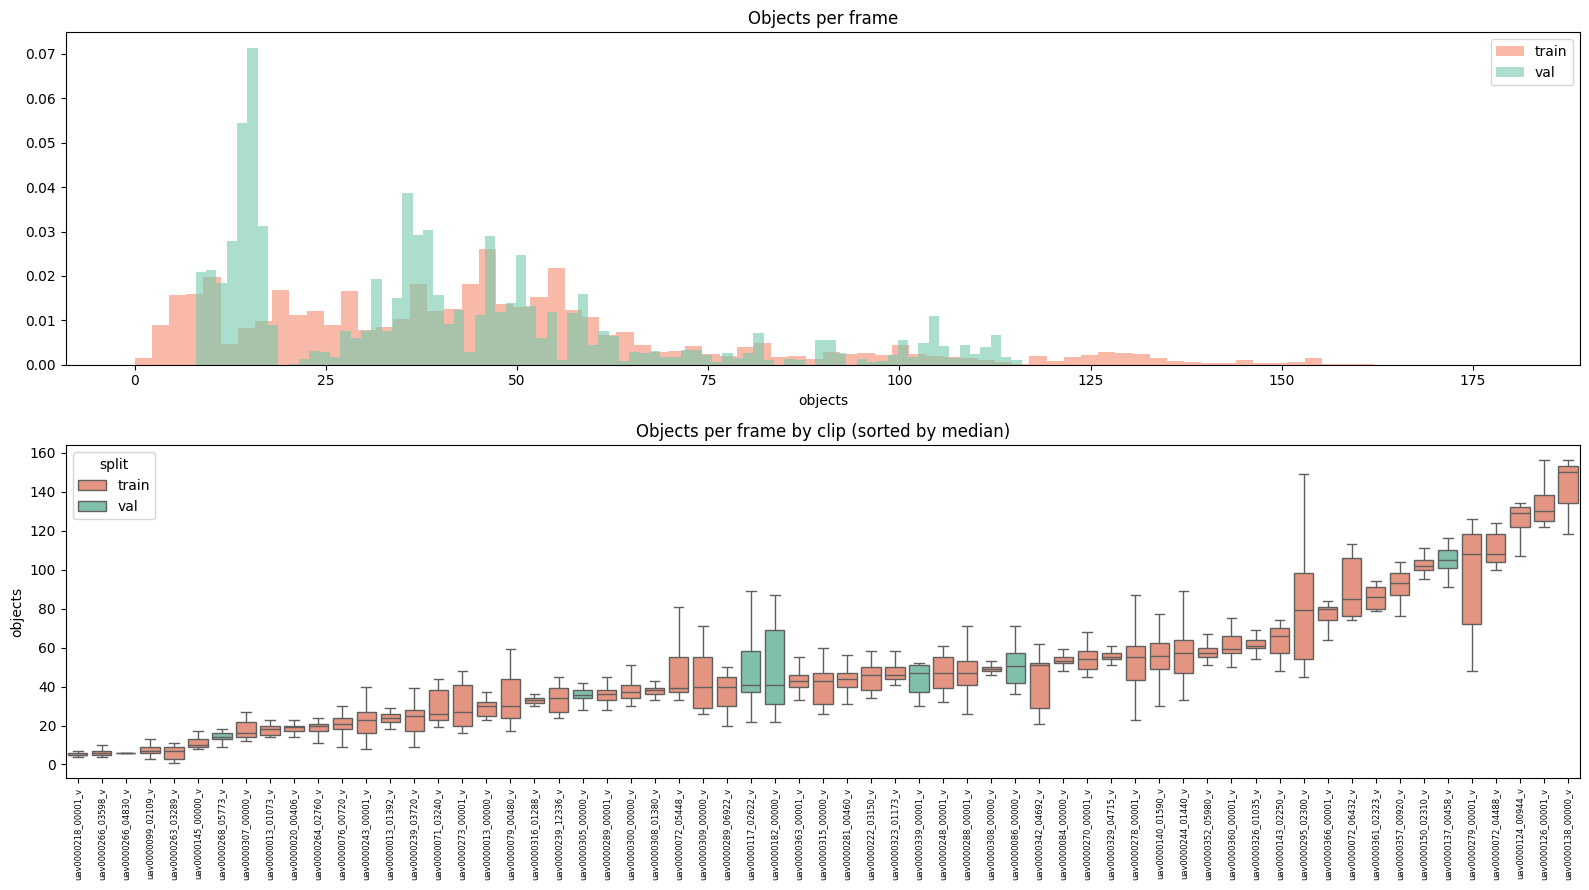

In [25]:
order = frames.groupby("video").n.median().sort_values().index
fig, ax = plt.subplots(2, 1, figsize=(16, 9))
for s, c in [("train", "#F58B70"), ("val", "#75C9AC")]:
    ax[0].hist(frames.loc[frames.split == s, "n"], bins=80, alpha=0.6, density=True, label=s, color=c)
ax[0].set(title="Objects per frame", xlabel="objects"); ax[0].legend()

sns.boxplot(data=frames, x="video", y="n", order=order, hue="split", showfliers=False, ax=ax[1], dodge=False,
            palette={"train": "#F58B70", "val": "#75C9AC"})
ax[1].set(title="Objects per frame by clip (sorted by median)", xlabel="", ylabel="objects")
ax[1].tick_params(axis="x", rotation=90, labelsize=6)
plt.tight_layout(); savefig("density"); plt.show()

**Observations:**
- 45.7 boxes per frame on average (median 43, p99 142, max 180); 7.5 % of frames have more than 100 objects, none more than 200. Density differs strongly between clips.
- A detector needs at least ~200 detections per image: torchvision's default of 100 would cut dense frames. 300 DETR queries already cover the maximum of 180, the 500-box scoring cap is never binding for the ground truth.

### Occlusion and truncation

VisDrone: occlusion 0 = none, 1 = partial (1–50 %), 2 = heavy (50–100 %); truncation 0 = none, 1 = partial.

In [26]:
for col in ["occlusion", "truncation"]:
    if col in objs:
        t = pd.crosstab(objs.cls_name, objs[col], normalize="index")
        t.loc["ALL"] = objs[col].value_counts(normalize=True)
        print(col); display((t * 100).round(1))

occlusion


occlusion,0.0,1.0,2.0
cls_name,,,
person,53.0,40.9,6.1
bicycle,41.7,55.1,3.2
car,56.2,38.9,4.9
van,54.9,41.5,3.5
truck,34.6,49.8,15.6
tricycle,41.7,55.6,2.6
bus,56.6,41.3,2.0
motor,51.9,41.7,6.4
ALL,53.1,41.5,5.5


truncation


truncation,0.0,1.0
cls_name,,
person,97.8,2.2
bicycle,99.0,1.0
car,94.2,5.8
van,94.3,5.7
truck,88.7,11.3
tricycle,95.8,4.2
bus,86.3,13.7
motor,96.7,3.3
ALL,95.6,4.4


**Observations:**
- 53 % of objects are not occluded, 41.5 % partially, 5.5 % heavily. Trucks are the most occluded (15.6 % heavy), the others have 2-6 %.
- Truncation by the frame border is rare (4.4 %), but higher for the large classes bus (13.7 %) and truck (11.3 %).
- Both fields exist only for train / val, not for test. Not used for training, kept for the failure analysis.

### Ignored regions

Ignored regions mark crowds, dense parking lots and VisDrone "others". They are not scored.
Here: how often they appear, how much of the frame they cover, and how many annotated boxes overlap them.

In [27]:
ign["area"] = ign.w * ign.h
ig = ign.groupby(["split", "image_id"]).agg(n_ign=("area", "size"), ign_area=("area", "sum")).reset_index()
frames = frames.drop(columns=["n_ign", "ign_area"], errors="ignore").merge(ig, on=["split", "image_id"], how="left")
frames[["n_ign", "ign_area"]] = frames[["n_ign", "ign_area"]].fillna(0)
frames["ign_frac"] = (frames.ign_area / (frames.width * frames.height)).clip(upper=1)

display(frames.groupby("split").agg(frames_with_ignore=("n_ign", lambda s: (s > 0).mean()),
                                    regions_per_frame=("n_ign", "mean"),
                                    mean_area_frac=("ign_frac", "mean"),
                                    p95_area_frac=("ign_frac", lambda s: s.quantile(.95))).round(3))

,frames_with_ignore,regions_per_frame,mean_area_frac,p95_area_frac
split,,,,
train,0.747,21.104,0.177,0.813
val,0.504,11.230,0.129,0.690


In [28]:
def ignore_cover(boxes, ign):
    # share of each box area covered by ignored regions (sum over regions, clipped to 1)
    m = boxes[["uid", "split", "image_id", "x", "y", "w", "h"]].merge(
        ign[["split", "image_id", "x", "y", "w", "h"]], on=["split", "image_id"], suffixes=("", "_i"))
    ix = (np.minimum(m.x + m.w, m.x_i + m.w_i) - np.maximum(m.x, m.x_i)).clip(lower=0)
    iy = (np.minimum(m.y + m.h, m.y_i + m.h_i) - np.maximum(m.y, m.y_i)).clip(lower=0)
    m["cover"] = ix * iy / (m.w * m.h).clip(lower=1e-6)
    cover = m.groupby("uid").cover.sum().clip(upper=1)
    return boxes.uid.map(cover).fillna(0).astype(np.float32)

objs["ign_cover"] = ignore_cover(objs, ign)
print("boxes touching an ignored region:", f"{(objs.ign_cover > 0).mean() * 100:.2f} %")
print("boxes >= 50 % inside an ignored region:", f"{(objs.ign_cover >= 0.5).mean() * 100:.2f} %")
display(pd.crosstab(objs.cls_name, objs.ign_cover >= 0.5, normalize="index").round(4) * 100)

boxes touching an ignored region: 3.49 %
boxes >= 50 % inside an ignored region: 2.73 %


ign_cover,False,True
cls_name,,
person,97.33,2.67
bicycle,98.05,1.95
car,96.98,3.02
van,95.55,4.45
truck,97.62,2.38
tricycle,97.53,2.47
bus,94.82,5.18
motor,98.86,1.14


**Observations:**
- Ignored regions are everywhere: 75 % of train frames have them (21 per frame on average), covering 18 % of the frame on average and 81 % at the 95th percentile.
- Only 3.5 % of boxes touch an ignored region and 2.7 % lie at least 50 % inside. These are dropped (6305 boxes in the exported frames) and the regions are grayed out. Bus (5.2 %) and van (4.5 %) are affected most.

### Temporal redundancy and frame subsampling

Consecutive frames are almost identical, so training on all 24k frames mostly repeats the same content.
For a step `k`: IoU of the same track (`track_id`) between frame `t` and `t + k`, center shift relative to box size,
and the share of tracks still seen when keeping every `k`-th frame.

,frames kept,"median IoU(t, t+k)",IoU > 0.7,median shift / box size,tracks covered
step,,,,,
1,24201,0.897,0.862,0.044,1.000
2,12114,0.810,0.671,0.085,0.996
3,8090,0.731,0.541,0.126,0.997
5,4868,0.597,0.397,0.209,0.993
8,3050,0.440,0.297,0.334,0.988
10,2446,0.357,0.259,0.416,0.986
15,1646,0.203,0.207,0.617,0.980
20,1238,0.102,0.180,0.807,0.967
30,838,0.000,0.149,1.159,0.954


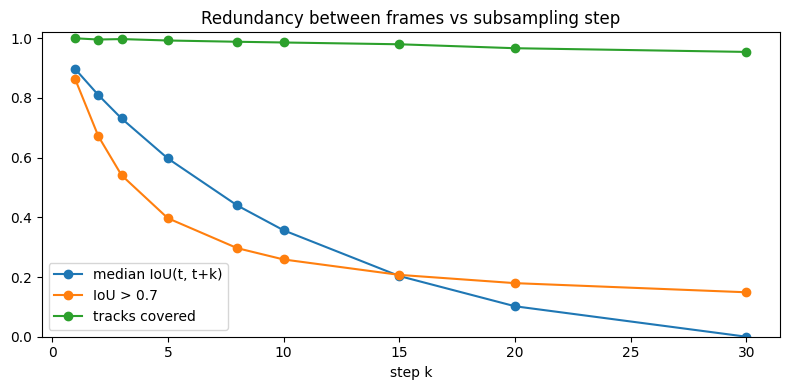

In [29]:
def sample_frames(img_df, step):
    # keep every step-th frame inside each clip (by rank, robust to gaps in frame_id)
    rank = img_df.groupby("video").frame_id.rank(method="first").astype(int) - 1
    return img_df[rank % step == 0]

def paired_iou(a, b):
    ix = (np.minimum(a[:, 0] + a[:, 2], b[:, 0] + b[:, 2]) - np.maximum(a[:, 0], b[:, 0])).clip(min=0)
    iy = (np.minimum(a[:, 1] + a[:, 3], b[:, 1] + b[:, 3]) - np.maximum(a[:, 1], b[:, 1])).clip(min=0)
    inter = ix * iy
    return inter / (a[:, 2] * a[:, 3] + b[:, 2] * b[:, 3] - inter)

tr_imgs = imgs[imgs.split == "train"]
tr = objs[objs.split == "train"][["image_id", "video", "track_id", "frame_id", "x", "y", "w", "h"]]
n_tracks = tr.groupby("video").track_id.nunique().sum()

rows = []
for k in [1, 2, 3, 5, 8, 10, 15, 20, 30]:
    nxt = tr.assign(frame_id=tr.frame_id - k)
    m = tr.merge(nxt, on=["video", "track_id", "frame_id"], suffixes=("", "_n"))
    a, b = m[["x", "y", "w", "h"]].to_numpy(), m[["x_n", "y_n", "w_n", "h_n"]].to_numpy()
    iou = paired_iou(a, b)
    shift = np.hypot((a[:, 0] + a[:, 2] / 2) - (b[:, 0] + b[:, 2] / 2),
                     (a[:, 1] + a[:, 3] / 2) - (b[:, 1] + b[:, 3] / 2)) / np.sqrt(a[:, 2] * a[:, 3])
    kept = sample_frames(tr_imgs, k)
    kept_tracks = tr[tr.image_id.isin(kept.image_id)].groupby("video").track_id.nunique().sum()
    rows.append({"step": k, "frames kept": len(kept), "median IoU(t, t+k)": np.median(iou),
                 "IoU > 0.7": (iou > 0.7).mean(), "median shift / box size": np.median(shift),
                 "tracks covered": kept_tracks / n_tracks})
temporal = pd.DataFrame(rows).set_index("step")
display(temporal.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
temporal[["median IoU(t, t+k)", "IoU > 0.7", "tracks covered"]].plot(ax=ax, marker="o")
ax.set(title="Redundancy between frames vs subsampling step", xlabel="step k", ylim=(0, 1.02))
plt.tight_layout(); savefig("temporal_redundancy"); plt.show()

**Observations / chosen step:**
- Neighbouring frames are almost duplicates: median IoU of the same object is 0.90 between t and t+1, 0.60 at t+5, 0.36 at t+10 and about 0 at t+30.
- Every 5th frame keeps 20 % of the frames (4868) but 99.3 % of the object tracks; step 10 would keep 98.6 % while objects move by 0.4 box sizes.
- **STEP = 5**: 5x less data for the GPU budget with almost no objects lost.

### Ground truth on raw frames

Boxes are colored by class, ignored regions are shaded red. One random frame from clips of different resolution.

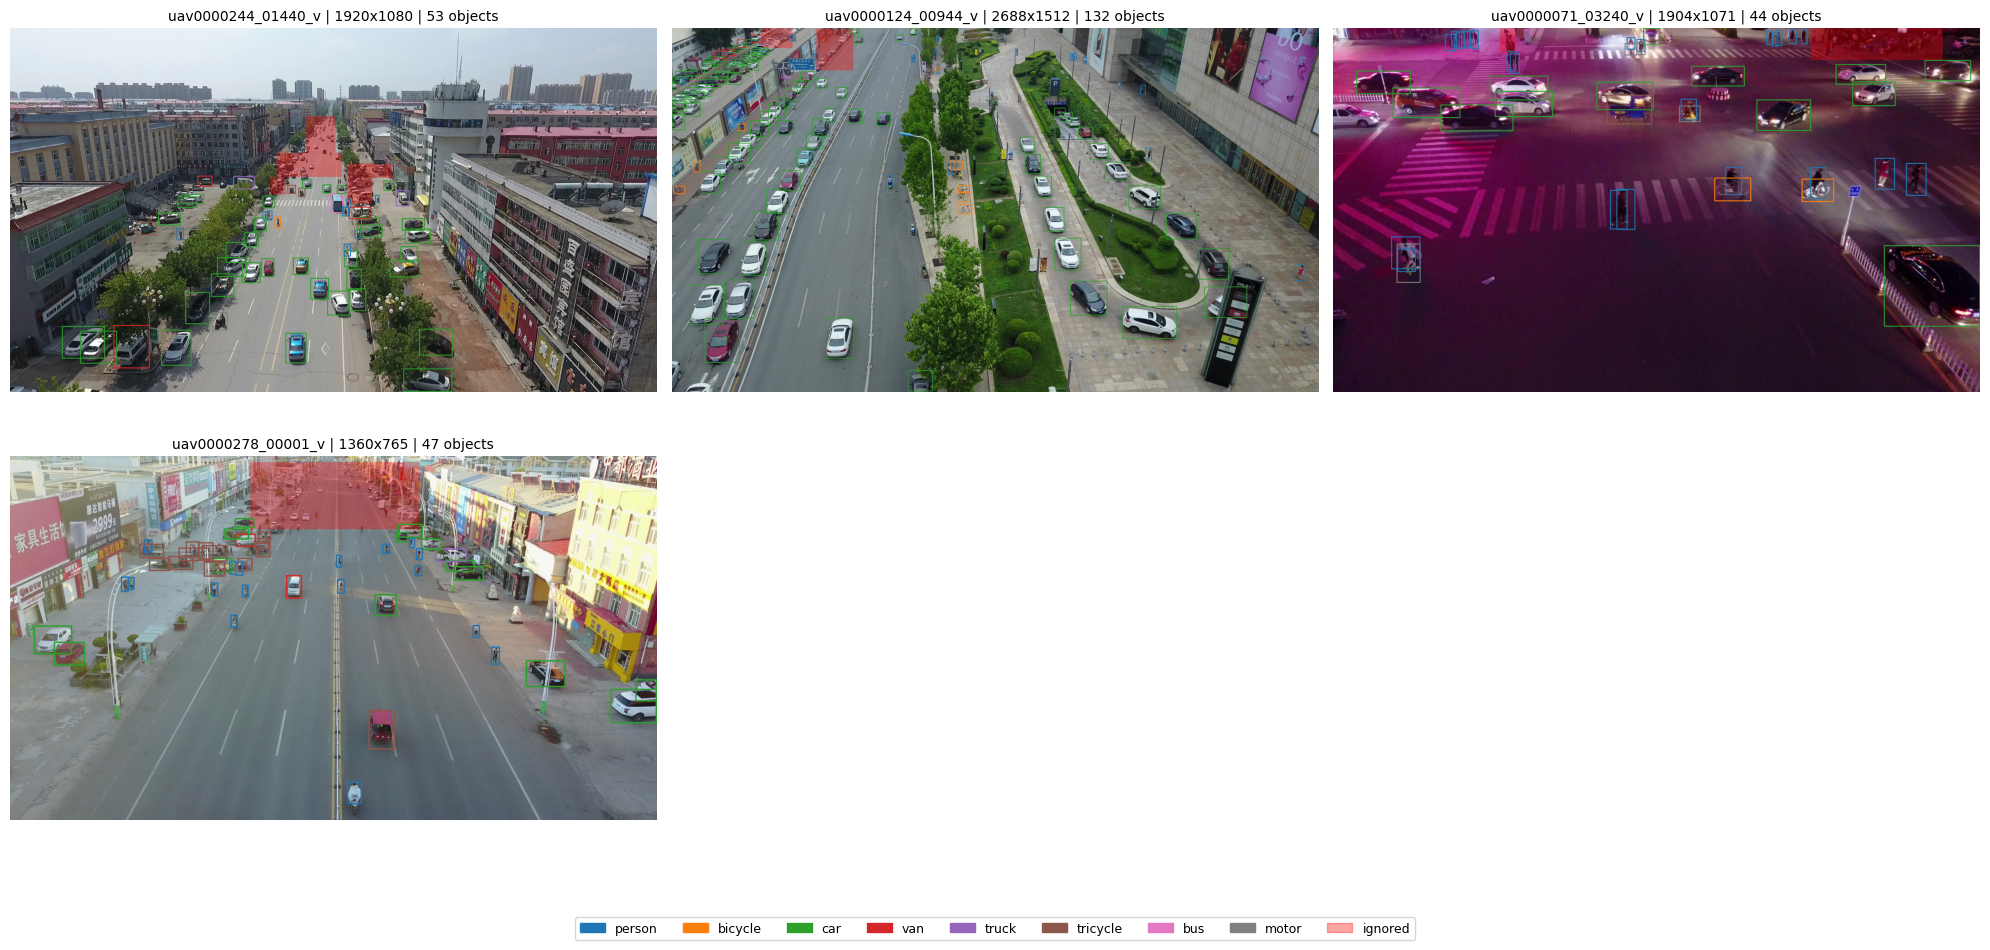

In [30]:
COLORS_BGR = [tuple(int(255 * c) for c in col[::-1]) for col in PALETTE]

def draw(img, boxes, ignore=None, thickness=2):
    # boxes: rows of (cls, x, y, w, h) in pixels; ignore: rows of (x, y, w, h)
    img = img.copy()
    if ignore is not None and len(ignore):
        over = img.copy()
        for x, y, w, h in ignore:
            cv2.rectangle(over, (int(x), int(y)), (int(x + w), int(y + h)), (0, 0, 255), -1)
        img = cv2.addWeighted(over, 0.35, img, 0.65, 0)
    for c, x, y, w, h in boxes:
        cv2.rectangle(img, (int(x), int(y)), (int(x + w), int(y + h)), COLORS_BGR[int(c)], thickness)
    return img[..., ::-1]

def legend(ax):
    handles = [mpatches.Patch(color=PALETTE[i], label=c) for i, c in enumerate(CLASSES)]
    handles.append(mpatches.Patch(color="red", alpha=0.35, label="ignored"))
    ax.legend(handles=handles, loc="lower center", ncol=9, bbox_to_anchor=(0.5, -0.08), fontsize=9)

# one frame from 6 clips with different resolutions
pick = (imgs[imgs.split == "train"].groupby("width").video.first().sample(6, random_state=SEED, replace=True).unique())
fig, axes = plt.subplots(2, 3, figsize=(20, 9))
for ax in axes.flat:
    ax.axis("off")
for ax, clip in zip(axes.flat, pick):
    r = imgs[(imgs.split == "train") & (imgs.video == clip)].sample(1, random_state=SEED).iloc[0]
    b = objs[(objs.split == "train") & (objs.image_id == r.image_id)]
    g = ign[(ign.split == "train") & (ign.image_id == r.image_id)]
    ax.imshow(draw(cv2.imread(r.path), b[["cls", "x", "y", "w", "h"]].to_numpy(), g[["x", "y", "w", "h"]].to_numpy()))
    ax.set_title(f"{clip} | {r.width}x{r.height} | {len(b)} objects", fontsize=10); ax.axis("off")
legend(fig); plt.tight_layout(); savefig("gt_raw_frames"); plt.show()

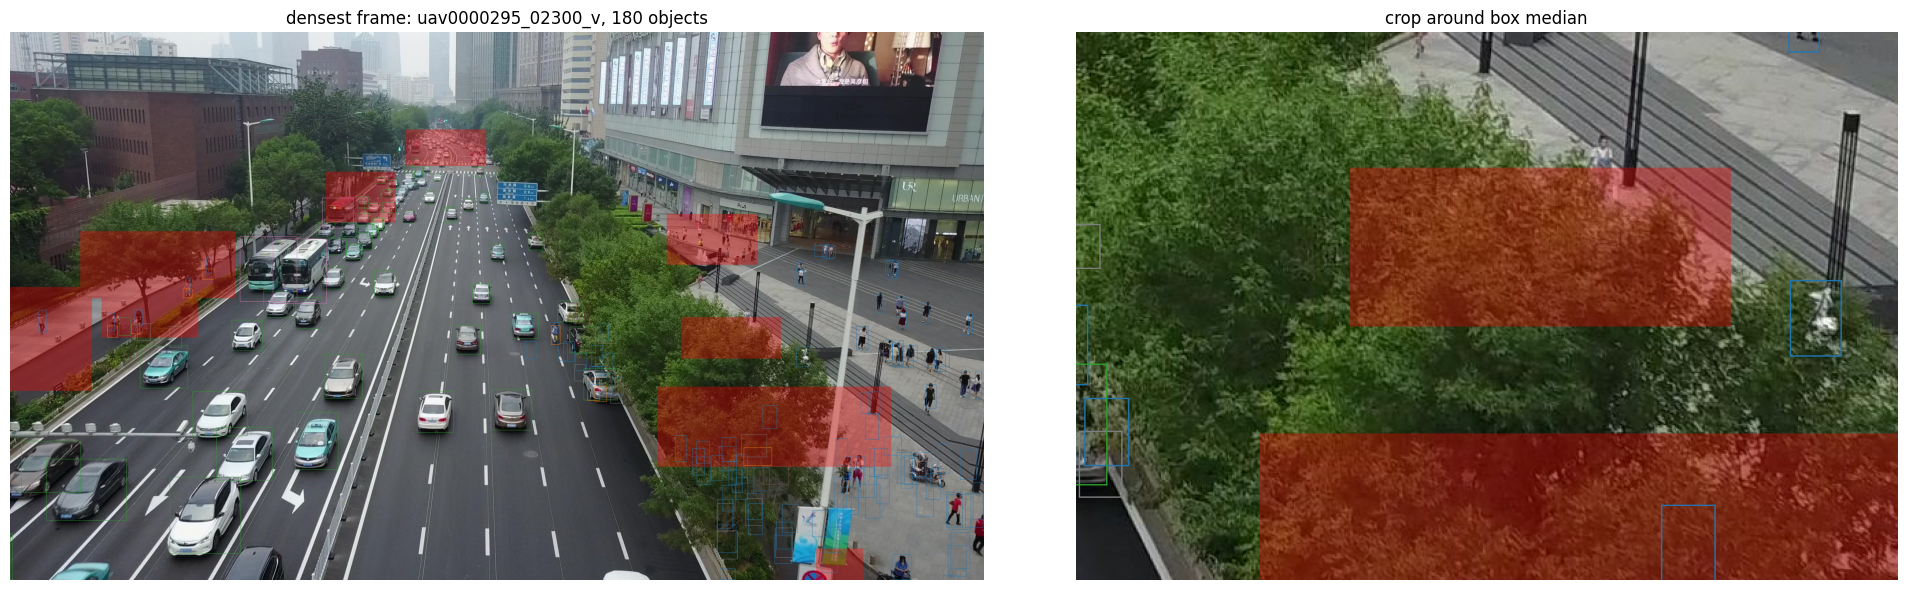

In [31]:
# zoomed crop of the densest train frame: are tiny objects annotated consistently?
r = frames[frames.split == "train"].sort_values("n").iloc[-1]
b = objs[(objs.split == "train") & (objs.image_id == r.image_id)]
g = ign[(ign.split == "train") & (ign.image_id == r.image_id)]
img = draw(cv2.imread(r.path), b[["cls", "x", "y", "w", "h"]].to_numpy(), g[["x", "y", "w", "h"]].to_numpy(), thickness=1)
cx, cy = int(b.x.median()), int(b.y.median())
h, w = img.shape[:2]
crop = img[max(0, cy - 200): cy + 200, max(0, cx - 300): cx + 300]
fig, ax = plt.subplots(1, 2, figsize=(20, 6))
ax[0].imshow(img); ax[0].set_title(f"densest frame: {r.video}, {r.n} objects"); ax[0].axis("off")
ax[1].imshow(crop); ax[1].set_title("crop around box median"); ax[1].axis("off")
plt.tight_layout(); savefig("gt_dense_frame"); plt.show()

### Validation design

Frames of one clip are highly correlated, so splits are made by **sequence**, never by frame.
VisDrone clip names encode the source flight (`uavXXXXXXX_XXXXX_v`): several clips can be cut from the same flight,
so clips are grouped by that prefix ("scene") to avoid leakage between folds.

Protocol for all detector notebooks: train on (subsampled) `train/` clips, evaluate on the provided `val/` clips
(7 clips, all frames, original resolution) with one shared COCO evaluator where ignored regions are `iscrowd = 1`.
Training 4 detector families × several tuning runs with K-fold CV is not affordable on Kaggle GPU quota,
so a fixed sequence-level hold-out is used; GroupKFold folds over train clips are saved for the final pipeline.

In [32]:
def scene_of(clip):
    m = re.match(r"(uav\d+)", clip)
    return m.group(1) if m else clip

clips = imgs.groupby("video").agg(split=("split", "first"), frames=("image_id", "size")).reset_index()
clips["scene"] = clips.video.map(scene_of)
shared = set(clips[clips.split == "train"].scene) & set(clips[clips.split == "val"].scene)
print("scenes:", clips.scene.nunique(), "| clips:", len(clips))
print("scenes shared between train and val:", sorted(shared) or "none")

scenes: 55 | clips: 63
scenes shared between train and val: none


In [33]:
# does val look like train? (class mix, size, density)
def profile(s):
    o, f = objs[objs.split == s], frames[frames.split == s]
    out = o.cls_name.value_counts(normalize=True).reindex(CLASSES).add_prefix("share ").to_dict()
    out.update({"small %": (o.size_bin == "small").mean() * 100, "median sqrt(area)": o.sqrt_area.median(),
                "median objects/frame": f.n.median(), "ignore area %": f.ign_frac.mean() * 100})
    return out
display(pd.DataFrame({s: profile(s) for s in ["train", "val"]}).round(3))

,train,val
share person,0.297,0.441
share bicycle,0.036,0.053
share car,0.457,0.279
share van,0.042,0.060
share truck,0.028,0.012
share tricycle,0.037,0.048
share bus,0.009,0.002
share motor,0.093,0.105
small %,24.907,19.197
median sqrt(area),45.826,52.393


In [34]:
from sklearn.model_selection import GroupKFold

N_FOLDS = 5
tr_clips = clips[clips.split == "train"].reset_index(drop=True)
folds = {}
for f, (_, va_idx) in enumerate(GroupKFold(N_FOLDS).split(tr_clips, groups=tr_clips.scene)):
    for clip in tr_clips.loc[va_idx, "video"]:
        folds[clip] = f
tr_clips["fold"] = tr_clips.video.map(folds)
display(tr_clips.groupby("fold").agg(clips=("video", "size"), scenes=("scene", "nunique"), frames=("frames", "sum")))

,clips,scenes,frames
fold,,,
0,12,10,5253
1,11,9,4027
2,11,9,4593
3,11,10,5306
4,11,10,5022


### Anchor statistics (for Faster R-CNN / RetinaNet)

Box shapes at the planned training resolution, IoU-based k-means (as in YOLOv2), and the share of GT boxes
that some anchor can match by shape alone (upper bound: centers assumed aligned, stride ignored).
torchvision `aspect_ratio` = h / w.

In [35]:
IMG_SZ = 1024   # planned training long side, choose from the resolution table above

tr = objs[objs.split == "train"]
scale = IMG_SZ / np.maximum(tr.width, tr.height)
wh_all = np.stack([tr.w * scale, tr.h * scale], 1).astype(np.float32)
wh = wh_all[rng.choice(len(wh_all), size=min(200_000, len(wh_all)), replace=False)]

def wh_iou(wh, anchors):
    inter = np.minimum(wh[:, None, 0], anchors[None, :, 0]) * np.minimum(wh[:, None, 1], anchors[None, :, 1])
    return inter / (wh[:, None].prod(2) + anchors[None].prod(2) - inter)

def kmeans_iou(wh, k, iters=100, seed=SEED):
    r = np.random.default_rng(seed)
    centers = wh[r.choice(len(wh), k, replace=False)]
    for _ in range(iters):
        assign = wh_iou(wh, centers).argmax(1)
        new = np.array([np.median(wh[assign == i], 0) if (assign == i).any() else centers[i] for i in range(k)])
        if np.allclose(new, centers):
            break
        centers = new
    return centers[np.argsort(centers.prod(1))]

KM = kmeans_iou(wh, 9)
print(f"k-means anchors (w, h) at long side {IMG_SZ}:\n", KM.round(1))
print("mean best IoU with k-means anchors:", wh_iou(wh, KM).max(1).mean().round(3))
print("h/w quantiles (10/50/90 %):", np.quantile(wh[:, 1] / wh[:, 0], [.1, .5, .9]).round(2))
print("sqrt(area) quantiles (5/25/50/75/95 %):", np.quantile(np.sqrt(wh.prod(1)), [.05, .25, .5, .75, .95]).round(1))

k-means anchors (w, h) at long side 1024:
 [[ 8.6 12.4]
 [11.3 22.1]
 [17.7 15.2]
 [16.1 31.7]
 [23.7 24.8]
 [33.1 18.3]
 [31.2 42.5]
 [51.6 28. ]
 [80.7 58.6]]
mean best IoU with k-means anchors: 0.728
h/w quantiles (10/50/90 %): [0.47 1.06 2.26]
sqrt(area) quantiles (5/25/50/75/95 %): [10.9 17.3 24.3 35.  66.6]


In [36]:
def anchor_set(base_sizes, ratios, octave_scales=(1.0,)):
    out = []
    for s0 in base_sizes:
        for sc in octave_scales:
            for r in ratios:
                s = s0 * sc
                out.append((s / np.sqrt(r), s * np.sqrt(r)))
    return np.array(out, dtype=np.float32)

RATIOS_DATA = tuple(np.round(np.quantile(wh[:, 1] / wh[:, 0], [.15, .5, .85]), 2))
OCT3 = (1.0, 2 ** (1 / 3), 2 ** (2 / 3))
anchor_cfgs = {
    "Faster R-CNN default (32..512, ratios .5/1/2)": anchor_set([32, 64, 128, 256, 512], (0.5, 1.0, 2.0)),
    "RetinaNet default (32..512 x3 scales)":          anchor_set([32, 64, 128, 256, 512], (0.5, 1.0, 2.0), OCT3),
    "small (8..128 x3 scales, ratios .5/1/2)":        anchor_set([8, 16, 32, 64, 128], (0.5, 1.0, 2.0), OCT3),
    f"small + data ratios {RATIOS_DATA}":              anchor_set([8, 16, 32, 64, 128], RATIOS_DATA, OCT3),
}
rows = []
for name, A in anchor_cfgs.items():
    best = wh_iou(wh, A).max(1)
    rows.append({"anchors": name, "n per location": len(A) // 5, "mean best IoU": best.mean(),
                 "matched IoU>=0.5": (best >= 0.5).mean(), "matched IoU>=0.4": (best >= 0.4).mean()})
display(pd.DataFrame(rows).set_index("anchors").round(3))

,n per location,mean best IoU,matched IoU>=0.5,matched IoU>=0.4
anchors,,,,
"Faster R-CNN default (32..512, ratios .5/1/2)",3,0.510,0.554,0.639
RetinaNet default (32..512 x3 scales),9,0.546,0.554,0.639
"small (8..128 x3 scales, ratios .5/1/2)",9,0.826,0.996,0.998
"small + data ratios (np.float64(0.53), np.float64(1.06), np.float64(2.04))",9,0.825,0.996,0.998


**Observations:**
- With the torchvision default anchors (32-512) only 55 % of boxes can be matched at IoU >= 0.5 (at 1024 long side, mean best IoU 0.55), because the median object is ~24 px. Anchors from 8 to 128 px match 99.6 % (mean best IoU 0.83).
- K-means with 9 anchors ranges from 9x12 to 81x59 px (mean best IoU 0.73).
- The data ratios (0.53 / 1.06 / 2.04) are close to the standard 0.5 / 1 / 2 and do not improve coverage (0.825 vs 0.826), so only the anchor sizes change.

### Preprocessing and export

Exported training set (built once here on CPU, reused by every GPU notebook):

- **Subsampling**: every `STEP`-th frame of each train clip (justified by the temporal table above).
- **Ignored regions**: pixels filled with gray (114) so the detector does not learn them as background; the fill is not applied
  inside annotated boxes that are kept. Boxes ≥ 50 % inside an ignored region are dropped (their pixels are hidden).
- **Resizing**: only downscaling, long side ≤ `MAX_SIDE` (INTER_AREA), aspect ratio kept. The final training size is set in each model notebook.
- **Labels**: YOLO txt (`class cx cy w h`, normalized, for Ultralytics) and COCO json (pixel coords of the exported image, 1-based categories, for torchvision). Ignored regions are also stored in the COCO json as `iscrowd = 1`, used only for evaluation.
- **Val / test are not modified**: raw frames at original resolution, val scored with ignored regions as `iscrowd = 1`, same as the leaderboard.

In [37]:
STEP = 5            # set from the temporal redundancy table
MAX_SIDE = 1280     # export long side (only downscale)
FILL = 114          # gray value for ignored regions
DROP_COVER = 0.5    # drop boxes with >= this share inside ignored regions

sel = sample_frames(imgs[imgs.split == "train"], STEP).copy()
sel["name"] = sel.video + "_" + sel.path.map(lambda p: Path(p).stem)
sel["scale"] = np.minimum(1.0, MAX_SIDE / np.maximum(sel.width, sel.height))
sel["new_w"] = (sel.width * sel.scale).round().astype(int)
sel["new_h"] = (sel.height * sel.scale).round().astype(int)

b = objs[(objs.split == "train") & objs.image_id.isin(sel.image_id)].copy()
# clip boxes to the image, drop degenerate ones
x0, y0 = b.x.clip(lower=0), b.y.clip(lower=0)
x1, y1 = np.minimum(b.x + b.w, b.width), np.minimum(b.y + b.h, b.height)
b["x"], b["y"], b["w"], b["h"] = x0, y0, x1 - x0, y1 - y0
valid = (b.w >= 1) & (b.h >= 1)
dropped_ign = valid & (b.ign_cover >= DROP_COVER)
keep = b[valid & ~dropped_ign]
g = ign[(ign.split == "train") & ign.image_id.isin(sel.image_id)]

print(f"frames: {len(sel)} | boxes kept: {len(keep)} | dropped (ignored region): {dropped_ign.sum()} "
      f"| dropped (degenerate): {(~valid).sum()}")

frames: 4868 | boxes kept: 216574 | dropped (ignored region): 6305 | dropped (degenerate): 0


In [38]:
for d in ["images/train", "labels/train"]:
    (OUT / d).mkdir(parents=True, exist_ok=True)

keep_by_img = {k: v[["cls", "x", "y", "w", "h"]].to_numpy() for k, v in keep.groupby("image_id")}
ign_by_img = {k: v[["x", "y", "w", "h"]].to_numpy() for k, v in g.groupby("image_id")}

def export_frame(task):
    path, name, boxes, ignore, new_w, new_h = task
    img = cv2.imread(path)
    H, W = img.shape[:2]
    if len(ignore):
        mask = np.zeros((H, W), bool)
        for x, y, w, h in ignore:
            mask[int(max(0, y)): int(np.ceil(y + h)), int(max(0, x)): int(np.ceil(x + w))] = True
        for _, x, y, w, h in boxes:            # keep pixels of retained objects
            mask[int(y): int(np.ceil(y + h)), int(x): int(np.ceil(x + w))] = False
        img[mask] = FILL
    if (new_w, new_h) != (W, H):
        img = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_AREA)
    cv2.imwrite(str(OUT / "images/train" / f"{name}.jpg"), img, [cv2.IMWRITE_JPEG_QUALITY, 95])
    # YOLO labels are normalized -> independent of the resize
    lines = [f"{int(c)} {(x + w / 2) / W:.6f} {(y + h / 2) / H:.6f} {w / W:.6f} {h / H:.6f}" for c, x, y, w, h in boxes]
    (OUT / "labels/train" / f"{name}.txt").write_text("\n".join(lines))
    return name

empty_b, empty_g = np.zeros((0, 5)), np.zeros((0, 4))
tasks = [(r.path, r.name, keep_by_img.get(r.image_id, empty_b), ign_by_img.get(r.image_id, empty_g), int(r.new_w), int(r.new_h))
         for r in sel.itertuples()]

t0 = time.time()
with Pool(os.cpu_count()) as pool:
    for _ in tqdm(pool.imap_unordered(export_frame, tasks, chunksize=16), total=len(tasks)):
        pass
print(f"exported {len(tasks)} frames in {time.time() - t0:.0f} s")

  0%|          | 0/4868 [00:00<?, ?it/s]

exported 4868 frames in 121 s


In [39]:
# COCO json for the exported train set (pixel coords of the resized image)
k = keep.merge(sel[["image_id", "scale"]], on="image_id")
coco_train = {
    "images": [{"id": int(r.image_id), "file_name": f"{r.name}.jpg", "width": int(r.new_w), "height": int(r.new_h),
                "video": r.video, "frame_id": int(r.frame_id)} for r in sel.itertuples()],
    "annotations": [{"id": i, "image_id": int(r.image_id), "category_id": int(r.cls) + 1,
                     "bbox": [round(r.x * r.scale, 2), round(r.y * r.scale, 2), round(r.w * r.scale, 2), round(r.h * r.scale, 2)],
                     "area": round(r.w * r.h * r.scale**2, 2), "iscrowd": 0} for i, r in enumerate(k.itertuples(), 1)],
    "categories": [{"id": i + 1, "name": c} for i, c in enumerate(CLASSES)],
}
# ignored regions go in as iscrowd=1, so the COCO evaluator skips detections inside them (same as val / leaderboard)
gs = g.merge(sel[["image_id", "scale"]], on="image_id")
n0 = len(coco_train["annotations"])
coco_train["annotations"] += [{"id": n0 + i, "image_id": int(r.image_id), "category_id": 1,
                               "bbox": [round(r.x * r.scale, 2), round(r.y * r.scale, 2), round(r.w * r.scale, 2), round(r.h * r.scale, 2)],
                               "area": round(r.w * r.h * r.scale**2, 2), "iscrowd": 1} for i, r in enumerate(gs.itertuples(), 1)]
print("crowd (ignored) regions in train_coco.json:", len(gs))
with open(OUT / "train_coco.json", "w") as f:
    json.dump(coco_train, f)
shutil.copy(VAL_DIR / "annotations_coco.json", OUT / "val_coco.json")   # untouched val GT (with iscrowd)

# everything later notebooks need, in one place
config = {
    "seed": SEED, "classes": CLASSES, "step": STEP, "max_side": MAX_SIDE, "fill": FILL, "drop_cover": DROP_COVER,
    "img_sz_planned": IMG_SZ,
    "anchors_kmeans_wh": KM.round(1).tolist(), "anchor_ratios_data": list(map(float, RATIOS_DATA)),
    "objects_per_frame": {"p50": float(frames.n.median()), "p99": float(frames.n.quantile(.99)), "max": int(frames.n.max())},
    "train_clips": sorted(tr_clips.video), "val_clips": sorted(clips[clips.split == "val"].video),
    "folds": folds,
    "normalization": {"torchvision": "ImageNet mean/std inside the model transform", "ultralytics": "/255"},
    "augmentation_plan": ["HorizontalFlip p=0.5", "Affine scale 0.8-1.2, translate 5 %", "RandomBrightnessContrast p=0.3",
                          "HueSaturationValue p=0.3", "Ultralytics: built-in mosaic / hsv / fliplr / scale"],
}
with open(OUT / "config.json", "w") as f:
    json.dump(config, f, indent=1)
print(json.dumps({k: v for k, v in config.items() if k not in ("folds", "train_clips")}, indent=1))

crowd (ignored) regions in train_coco.json: 103184
{
 "seed": 42,
 "classes": [
  "person",
  "bicycle",
  "car",
  "van",
  "truck",
  "tricycle",
  "bus",
  "motor"
 ],
 "step": 5,
 "max_side": 1280,
 "fill": 114,
 "drop_cover": 0.5,
 "img_sz_planned": 1024,
 "anchors_kmeans_wh": [
  [
   8.600000381469727,
   12.399999618530273
  ],
  [
   11.300000190734863,
   22.100000381469727
  ],
  [
   17.700000762939453,
   15.199999809265137
  ],
  [
   16.100000381469727,
   31.700000762939453
  ],
  [
   23.700000762939453,
   24.799999237060547
  ],
  [
   33.099998474121094,
   18.299999237060547
  ],
  [
   31.200000762939453,
   42.5
  ],
  [
   51.599998474121094,
   28.0
  ],
  [
   80.69999694824219,
   58.599998474121094
  ]
 ],
 "anchor_ratios_data": [
  0.53,
  1.06,
  2.04
 ],
 "objects_per_frame": {
  "p50": 42.0,
  "p99": 140.0,
  "max": 180
 },
 "val_clips": [
  "uav0000086_00000_v",
  "uav0000117_02622_v",
  "uav0000137_00458_v",
  "uav0000182_00000_v",
  "uav0000268_05773_

##### Verify the export

In [40]:
# 1) provided YOLO labels vs COCO: same number of objects per frame?
def n_lines(p):
    return sum(1 for l in open(p) if l.strip()) if p.exists() else 0

def load_labels(name):
    # (n, 5) array, also for empty label files
    return np.array((OUT / "labels/train" / f"{name}.txt").read_text().split(), dtype=np.float64).reshape(-1, 5)

chk = sel.sample(min(500, len(sel)), random_state=SEED)
provided = chk.path.map(lambda p: n_lines(TRAIN_DIR / "labels" / Path(p).parent.name / (Path(p).stem + ".txt")))
coco_n = chk.image_id.map(b.groupby("image_id").size()).fillna(0).astype(int)
print("frames where provided YOLO count != COCO count:", (provided.values != coco_n.values).sum(), "of", len(chk))

# 2) exported labels: count matches the kept boxes, all coords in [0, 1]
lab = [load_labels(n) for n in sel.name]
n_exp = sum(len(l) for l in lab)
allv = np.concatenate([l for l in lab if len(l)])
print("exported boxes:", n_exp, "| expected:", len(keep), "| coords in [0,1]:", bool(((allv[:, 1:] >= 0) & (allv[:, 1:] <= 1)).all()))
print("exported images:", len(list((OUT / "images/train").glob("*.jpg"))))

frames where provided YOLO count != COCO count: 0 of 500
exported boxes: 216574 | expected: 216574 | coords in [0,1]: True
exported images: 4868


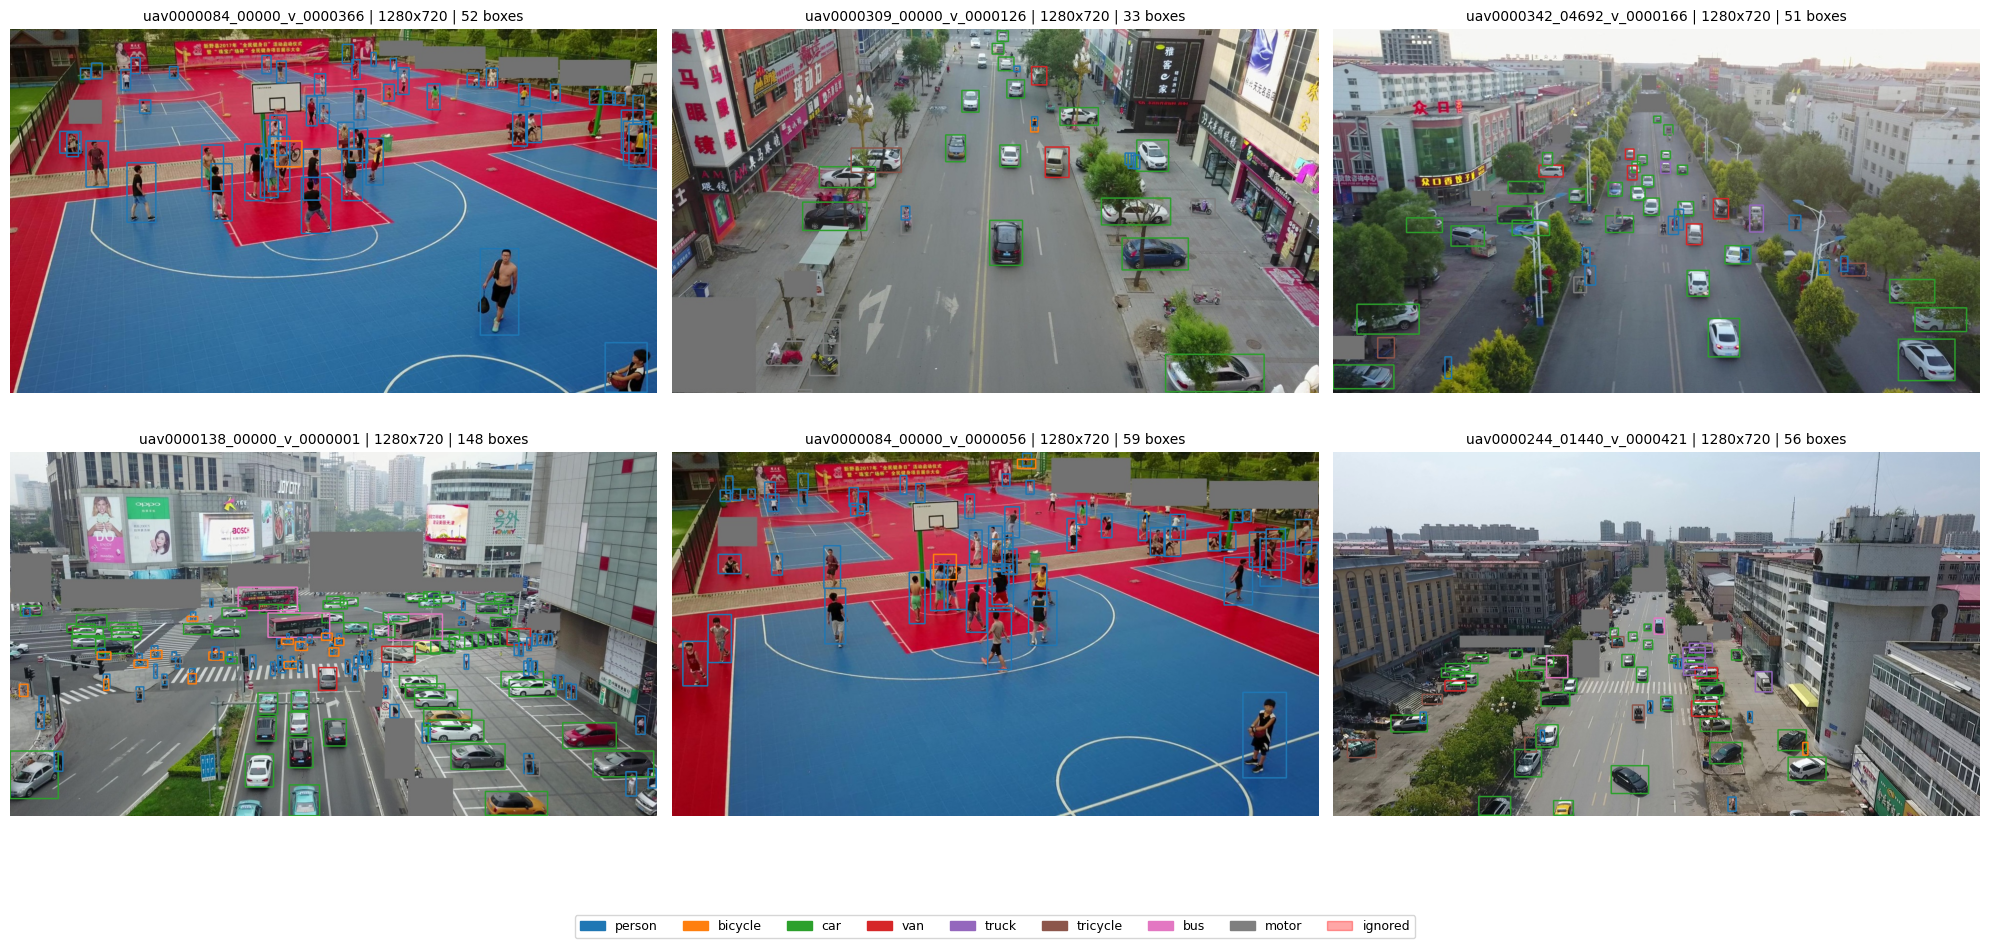

In [41]:
# 3) draw exported images with the exported labels read back from disk (gray = masked ignored regions)
def read_yolo(name, w, h):
    l = load_labels(name)
    return np.stack([l[:, 0], (l[:, 1] - l[:, 3] / 2) * w, (l[:, 2] - l[:, 4] / 2) * h, l[:, 3] * w, l[:, 4] * h], 1)

with_ign = sel[sel.image_id.isin(g.image_id)]
show = pd.concat([with_ign.sample(min(3, len(with_ign)), random_state=SEED),
                  sel.sample(3, random_state=SEED + 1)])
fig, axes = plt.subplots(2, 3, figsize=(20, 9))
for ax, r in zip(axes.flat, show.itertuples()):
    img = cv2.imread(str(OUT / "images/train" / f"{r.name}.jpg"))
    h, w = img.shape[:2]
    bx = read_yolo(r.name, w, h)
    ax.imshow(draw(img, bx)); ax.set_title(f"{r.name} | {w}x{h} | {len(bx)} boxes", fontsize=10); ax.axis("off")
legend(fig); plt.tight_layout(); savefig("export_check"); plt.show()

##### Augmentation check

The augmentations planned for the torchvision models, applied with box transforms. Boxes must stay aligned with objects.

/usr/local/lib/python3.13/dist-packages/albumentations/check_version.py:147: UserWarning: Error fetching version info <urlopen error [Errno -3] Temporary failure in name resolution>
  data = fetch_version_info()


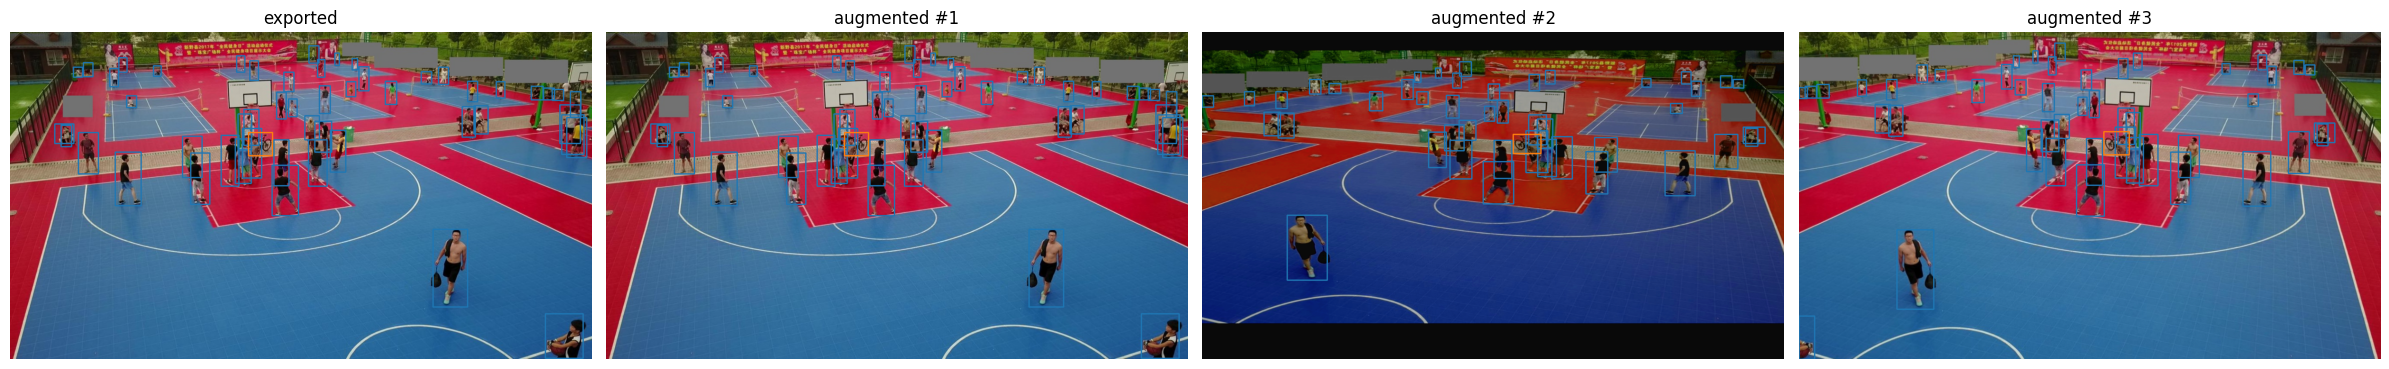

In [42]:
import albumentations as A

aug_list = [
    A.HorizontalFlip(p=0.5),
    A.Affine(scale=(0.8, 1.2), translate_percent=(-0.05, 0.05), p=0.5),
    A.RandomBrightnessContrast(p=0.3),
    A.HueSaturationValue(p=0.3),
]
bbox_params = A.BboxParams(format="coco", label_fields=["cls"], min_visibility=0.3)
try:
    aug = A.Compose(aug_list, bbox_params=bbox_params, seed=SEED)   # albumentations >= 1.4.x
except TypeError:
    aug = A.Compose(aug_list, bbox_params=bbox_params)

r = show.iloc[0]
img = cv2.imread(str(OUT / "images/train" / f"{r['name']}.jpg"))
bx = read_yolo(r["name"], img.shape[1], img.shape[0])
bx[:, 1:3] = bx[:, 1:3].clip(min=0)                               # float safety for strict bbox checks
bx[:, 3] = np.minimum(bx[:, 3], img.shape[1] - bx[:, 1]); bx[:, 4] = np.minimum(bx[:, 4], img.shape[0] - bx[:, 2])
fig, axes = plt.subplots(1, 4, figsize=(24, 5))
axes[0].imshow(draw(img, bx)); axes[0].set_title("exported"); axes[0].axis("off")
random.seed(SEED); np.random.seed(SEED)
for i, ax in enumerate(axes[1:]):
    out = aug(image=img, bboxes=bx[:, 1:].tolist(), cls=bx[:, 0].tolist())
    ob = np.column_stack([out["cls"], np.array(out["bboxes"]).reshape(-1, 4)])
    ax.imshow(draw(out["image"], ob)); ax.set_title(f"augmented #{i + 1}"); ax.axis("off")
plt.tight_layout(); savefig("augmentation_check"); plt.show()

### Save outputs

Everything is already in `/kaggle/working`: `vd_prep/` (images, labels, `train_coco.json`, `val_coco.json`, `config.json`) and `figures/`.

To reuse it: **Save Version → Save & Run All**, then in each GPU notebook **Add Input → Notebook Output Files** → this notebook.
It appears there as `/kaggle/input/<this-notebook-name>/vd_prep`.

In [47]:
!du -sh {OUT} {FIG_DIR}
!ls {OUT}

1.7G	/kaggle/working/vd_prep
11M	/kaggle/working/figures
config.json  images  labels  train_coco.json  val_coco.json


### Summary

In [46]:
summary = {
    "train clips / frames": f"{(clips.split == 'train').sum()} / {(imgs.split == 'train').sum()}",
    "val clips / frames": f"{(clips.split == 'val').sum()} / {(imgs.split == 'val').sum()}",
    "test clips / frames": f"{test['clip'].nunique()} / {len(test)}",
    "most / least frequent class": f"{share['train'].idxmax()} / {share['train'].idxmin()}",
    "COCO-small share": f"{(objs.size_bin == 'small').mean() * 100:.1f} %",
    "median sqrt(area), px": f"{objs.sqrt_area.median():.1f}",
    "objects/frame median / p99 / max": f"{frames.n.median():.0f} / {frames.n.quantile(.99):.0f} / {frames.n.max()}",
    "frames with ignored regions": f"{(frames.n_ign > 0).mean() * 100:.1f} %",
    "subsampling step / exported frames": f"{STEP} / {len(sel)}",
}
display(pd.Series(summary, name="value").to_frame())

,value
train clips / frames,56 / 24201
val clips / frames,7 / 2846
test clips / frames,48 / 3811
most / least frequent class,car / bus
COCO-small share,24.4 %
"median sqrt(area), px",46.4
objects/frame median / p99 / max,42 / 140 / 180
frames with ignored regions,72.2 %
subsampling step / exported frames,5 / 4868


**Decisions carried into the model notebooks:**
- Validation: split by clip, val and train share no flight (checked). 5 GroupKFold folds over the 56 train clips (~11 clips each, saved in `config.json`), final check on the official val (note: more persons, fewer cars, one 4K clip).
- Data: every 5th frame (4868 frames), ignored regions grayed out, 6305 boxes inside them dropped, frames exported with long side <= 1280.
- Input size: objects are small, so use the largest affordable size: 960 long side for the torchvision models, 640 vs 960 compared for YOLO.
- Anchors: small sizes taken from the box-size quantiles (about 8-128 px at 1024), ratios 0.5 / 1 / 2 unchanged.
- Detections per image: 500 (scoring cap, GT max is 180). DETR queries: 300 are enough by count, 500 is tested.
- Augmentation: flip and brightness / contrast for the torchvision models, built-in mosaic / HSV / flip / scale for YOLO and RT-DETR. Scale jitter would help (object scale varies 3x between clips) but is not used in notebooks 2-3 for simplicity.